# Function 2 - Week 5: cohort model review and next-query comparison

Start with the [cohort exploration review](cohort-exploration-review.ipynb). This copy uses the
current **14 official observations plus five audited peer returns** from the retained
20 October 2026 snapshot: **19 observations** in total. Our own feedback is current through
round 4, received on 23 October. The shared initial ten rows are included once.

Keep the same seven declared model families, GP bounds, noise assumption and acquisition
settings as the [official model notebook](model_predictions.ipynb). Compare predictive checks,
the proposed input and sensitivity. A final paired comparison scores the same 14 official
held-out targets and a common candidate pool to distinguish data changes from evaluation changes.

Peer returns are published self-reports, with possible rounding or transcription errors.
The snapshot was not refreshed from GitHub. No portal query or change to the official
proposal is made here. The local data audit retains pinned source commits and checksums.


In [2]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.spatial import Delaunay
from scipy.spatial.distance import cdist
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

week_dir = Path.cwd().resolve()
if not (week_dir / 'cohort-model_predictions.ipynb').is_file() or not (week_dir / 'cohort-observations.csv').is_file():
    raise FileNotFoundError('Run from Function_2/Week_05 with the notebook and observations.csv together.')
shared_dir = week_dir.parents[1] / 'Shared'
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from model_helpers import compare_models, make_query_candidates, score_query_candidates, gp_slice
from coverage_helpers import make_coverage_space
from coverage_cache import compare_coverage_batches
from query_budget import remaining_queries, TOTAL_QUERY_WEEKS
from plot_helpers import PLOT_CONFIG
from two_input_model_helpers import (
    outline_hull, plot_gp_slice, prediction_grid, plot_contour_comparison, fitted_terrain,
)
figures = week_dir / 'figures' / 'cohort'
figures.mkdir(parents=True, exist_ok=True)
print('Kernel:', sys.executable)


Kernel: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


## 1. Define the goal and scope

Explore how the five previously accepted peer returns change the Function 2 fit and next-query
proposal, while retaining the official 14-row record and strategy. Nine own weekly query
opportunities remain, including Week 5; peer observations do not increase that allowance.

## 2. Gather the data

Use `cohort-observations.csv`: the current 14 official rows followed by five accepted peer rows
from [the previous pooled study](../../../side-quests/cohort-2026-10-20/README.md). Source checksums
were checked against the retained files. The shared initial rows are included once; compatible
duplicates, pending outputs and coordinates reported as 1.000000 remain excluded. Distinct
inputs with equal reported outputs are retained. No missing value is guessed or clipped.


In [3]:
data = pd.read_csv(week_dir / 'cohort-observations.csv', float_precision='round_trip')
own_data = pd.read_csv(week_dir / 'observations.csv', float_precision='round_trip')
input_columns = ['x1', 'x2']
output_column = 'y'
expected_columns = ['observation_id', 'source_round', *input_columns, 'y']
if list(data.columns) != expected_columns or len(data) != 19 or len(own_data) != 14:
    raise ValueError('Expected 14 official rows plus the five retained peer observations.')
if data.isna().any().any() or not data.observation_id.is_unique:
    raise ValueError('Require complete observations with distinct IDs.')
pd.testing.assert_frame_equal(data.iloc[:len(own_data)].reset_index(drop=True), own_data)
own_mask = data.observation_id.isin(own_data.observation_id).to_numpy()
peer_mask = data.observation_id.str.startswith('peer-').to_numpy()
assert int(own_mask.sum()) == 14 and int(peer_mask.sum()) == 5 and (own_mask | peer_mask).all()
assert data.loc[own_mask, 'source_round'].value_counts().to_dict() == {0:10, 1:1, 2:1, 3:1, 4:1}
assert int(data.loc[peer_mask, 'source_round'].max()) <= 2
X, y = data[input_columns], data[output_column]
inputs, raw_y = X.to_numpy(dtype=float), y.to_numpy(dtype=float)
if not np.isfinite(np.column_stack([inputs, raw_y])).all() or not ((inputs >= 0) & (inputs < 1)).all():
    raise ValueError('Require finite observations with inputs in [0, 1).')
print(f'{len(data)} observations: {own_mask.sum()} official plus {peer_mask.sum()} peer rows.')
print(f'Owner query allowance including Week 5: {remaining_queries(week_dir)} of {TOTAL_QUERY_WEEKS}.')


19 observations: 14 official plus 5 peer rows.
Owner query allowance including Week 5: 9 of 13.


## 3. Explore the data

The [cohort exploration review](cohort-exploration-review.ipynb) displays the expanded data.
The owner's latest return is **0.1311943186340309**, rank **11/19 (1 = highest output)**.
The incumbent is still **0.6112052157614438** from the initial ten observations.
Identify the owner's round 4 row explicitly; peer iterations are not an owner query history.


In [4]:
# Identify the one new observation in this week's accumulated data.
latest_round = int(own_data["source_round"].max())
latest_indices = data.index[own_mask & data["source_round"].eq(latest_round)]
if latest_round == 0 or len(latest_indices) != 1:
    raise ValueError("This weekly comparison expects one latest returned observation.")
latest_index = latest_indices[0]
latest_position = X.index.get_loc(latest_index)
latest_output = float(y.loc[latest_index])
other_observations = data["observation_id"].ne(data.loc[latest_index, "observation_id"]).to_numpy()

print(f"Latest observation: {data.loc[latest_index, 'observation_id']}")
print(f"Latest output: {latest_output:.6f}")
print(f"Previous best: {y.loc[data['source_round'].lt(latest_round)].max():.6f}")
print("Maximise the original signed output; retain negative and positive results.")
data.loc[[latest_index], ["observation_id", *input_columns, output_column]]

Latest observation: round-04
Latest output: 0.131194
Previous best: 0.611205
Maximise the original signed output; retain negative and positive results.


,observation_id,x1,x2,y
13,round-04,0.17954,0.808737,0.131194


## 4. Clean and preprocess the data

Preserve every observation, its sign and full float64 precision. Inputs already share the
range `[0, 1)`; retain the higher-dimensional comparison's preprocessing. GP target
normalisation and kernel fitting happen separately inside each training fold. The assumed
noise SD is 10% of the training target SD; it is not an estimated measurement-noise level.

## 5. Select and engineer features

Retain `x1, x2` for the full models and an explicit x1-only ablation from the earlier
Function 2 study. That hypothesis omits x2 only inside its pipeline; no source observations
are changed. No engineered features or target transform are introduced. Kernel ridge and the GP can represent curved relationships without adding
hand-picked predictors.

## 6. Define the machine-learning task

Regress the numerical output to support maximisation. Predicting observed outputs accurately
and locating a better unseen maximum are different assessments.

## 7. Partition the data

Use 19 leave-one-out folds, training on 18 observations and scoring the held-out one.
A separate final test set is not used for this small adaptive study. The latest-result fold
uses the 13 earlier official rows plus five frozen peer observations; its settings are declared now, so this remains a retrospective
check rather than a historical forecast. Reusing the folds to compare models makes the winning
error an optimistic estimate of future performance.

## 8. Select and train candidate methods

Retain the Functions 4–8 comparison settings: mean baseline, ordinary linear regression,
ridge (`alpha=1`), RBF kernel ridge (`alpha=0.1`, `gamma=1`), and a GP with a constant-times-RBF
kernel, fitted length scale, 10% noise assumption and three seeded optimiser restarts.
Report RMSE and MAE in original output units; fit the final models on all 19 rows only after
collecting held-out predictions.

The two Function 2 alternatives use the same fitted GP settings: an **x1-only GP** (select x1 inside each training pipeline), and a **separate-length-scale GP** (fit one RBF length scale per coordinate). All three GPs use the same declared noise fraction. These are pre-existing hypotheses, not a search over new settings until one wins.

Peer points are self-selected and can cluster near strong observations. Their reported precision
and noise may differ. Retain the original 10% training-target-SD noise assumption as a controlled
comparison, not a calibrated noise model. Pooled LOO metrics use different targets from the official
14-row metrics; compare the paired official-target scores at the end before inferring improvement.


In [5]:
noise_fraction = 0.10
models = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'Linear regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Kernel ridge': KernelRidge(alpha=0.1, kernel='rbf', gamma=1.0),
    'Gaussian process': GaussianProcessRegressor(
        kernel=ConstantKernel(1.0, (0.01, 100.0)) * RBF(0.3, (0.03, 2.0)),
        alpha=noise_fraction ** 2, normalize_y=True,
        n_restarts_optimizer=3, random_state=42,
    ),
}
models['GP: x1 only'] = make_pipeline(
    ColumnTransformer([('x1', 'passthrough', [0])], remainder='drop'),
    clone(models['Gaussian process']),
)
models['GP: separate length scales'] = clone(models['Gaussian process']).set_params(
    kernel=ConstantKernel(1.0, (0.01, 100.0)) * RBF([0.3, 0.3], (0.03, 2.0)),
)
comparison, held_out_predictions, fitted_models = compare_models(models, inputs, raw_y)
baseline_rmse = float(comparison.loc['Mean baseline', 'LOO RMSE'])
gp_names = ['Gaussian process', 'GP: x1 only', 'GP: separate length scales']
best_gp_name = comparison.loc[gp_names, 'LOO RMSE'].idxmin()
gaussian_process_rmse = float(comparison.loc[best_gp_name, 'LOO RMSE'])
model_comparison = comparison.reset_index()
model_comparison['RMSE reduction (%)'] = 100 * (1 - model_comparison['LOO RMSE'] / baseline_rmse)
model_comparison = model_comparison.sort_values('LOO RMSE').reset_index(drop=True)
display(model_comparison.round(6))


C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a bette

C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a bette

C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


,Model,Training MAE,LOO MAE,LOO RMSE,MAE / baseline,RMSE reduction (%)
0,GP: x1 only,0.006999,0.095368,0.123776,0.467994,47.676714
1,GP: separate length scales,0.005791,0.108759,0.133602,0.533706,43.523037
2,Gaussian process,0.003829,0.144395,0.176587,0.708579,25.352506
3,Kernel ridge,0.126034,0.165013,0.214178,0.809757,9.461958
4,Ridge,0.157726,0.177604,0.221978,0.871540,6.164340
5,Linear regression,0.149570,0.176797,0.229838,0.867583,2.841987
6,Mean baseline,0.193056,0.203781,0.236561,1.000000,0.000000


In [6]:
# Inspect the latest-result fold: train on other retained observations and predict the new one.
# Model settings were chosen for this analysis, so this is a retrospective check.
# The other-row metric below uses folds that include the latest observation in training.
latest_rows = []
for name, predictions in held_out_predictions.items():
    residuals = predictions - y.to_numpy()
    latest_prediction = float(predictions[latest_position])
    latest_error = latest_prediction - latest_output
    latest_rows.append({
        "Model": name,
        "Latest held-out prediction": latest_prediction,
        "Latest error": latest_error,
        "Latest absolute error (%)": 100 * abs(latest_error) / abs(latest_output),
        "Latest share of squared error (%)": 100 * latest_error ** 2 / np.sum(residuals ** 2),
        "Other rows LOO RMSE": root_mean_squared_error(
            y.to_numpy()[other_observations], predictions[other_observations],
        ),
    })
latest_prediction_review = pd.DataFrame(latest_rows).sort_values("Latest absolute error (%)").reset_index(drop=True)
print(f"Actual latest output: {latest_output:.6f}")
print(f"Each prediction of this latest output used only the {other_observations.sum()} other retained observations.")
print("Other rows LOO RMSE excludes this row from scoring, not from their training folds.")
latest_prediction_review.round(4)

Actual latest output: 0.131194
Each prediction of this latest output used only the 18 other retained observations.
Other rows LOO RMSE excludes this row from scoring, not from their training folds.


,Model,Latest held-out prediction,Latest error,Latest absolute error (%),Latest share of squared error (%),Other rows LOO RMSE
0,Linear regression,0.0989,-0.0323,24.6240,0.1040,0.2360
1,Kernel ridge,0.1680,0.0368,28.0174,0.1550,0.2199
2,Ridge,0.1754,0.0442,33.6790,0.2085,0.2278
3,Mean baseline,0.2124,0.0812,61.9040,0.6203,0.2423
4,Gaussian process,0.2124,0.0812,61.9043,1.1133,0.1804
5,GP: separate length scales,0.2124,0.0812,61.9048,1.9449,0.1359
6,GP: x1 only,-0.0368,-0.1680,128.0584,9.6965,0.1208


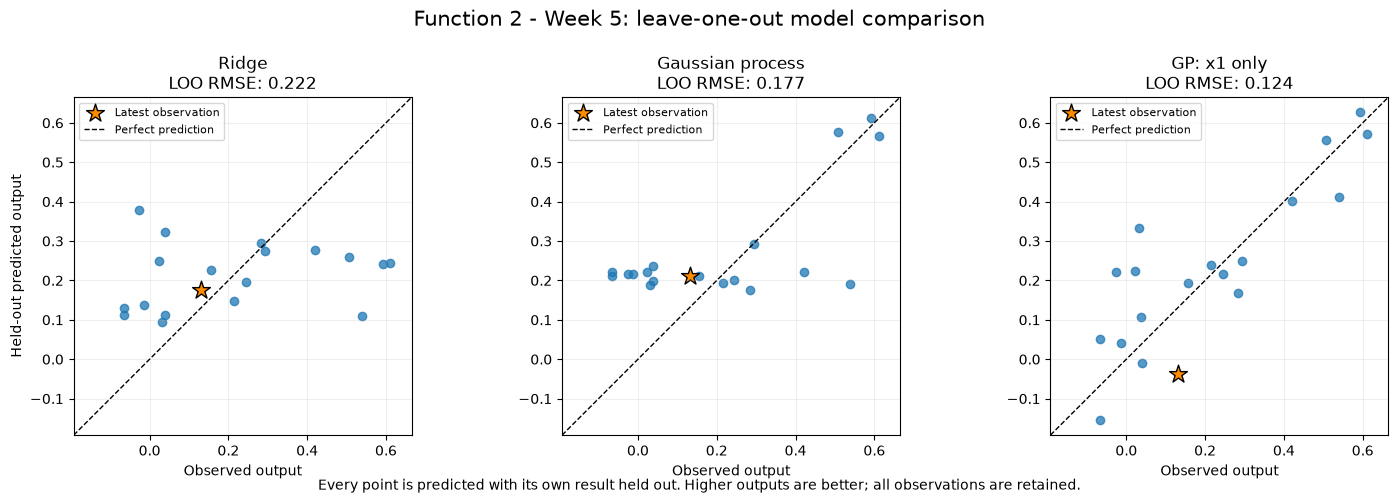

In [7]:
# Compare the linear and nonlinear alternatives on the same output scale.
plot_models = ["Ridge", "Gaussian process", best_gp_name]
plot_values = np.concatenate([
    y.to_numpy(), *(held_out_predictions[name] for name in plot_models),
])
plot_padding = 0.05 * np.ptp(plot_values)
plot_limits = (
    float(plot_values.min() - plot_padding),
    float(plot_values.max() + plot_padding),
)

fig, axes = plt.subplots(1, len(plot_models), figsize=(15, 5))
for ax, name in zip(axes, plot_models):
    predictions = held_out_predictions[name]
    ax.scatter(y.to_numpy()[other_observations], predictions[other_observations], alpha=0.75)
    ax.scatter(
        latest_output, predictions[latest_position], marker="*", s=180,
        color="darkorange", edgecolor="black", label="Latest observation",
    )
    ax.plot(plot_limits, plot_limits, "k--", linewidth=1, label="Perfect prediction")
    ax.set(
        xlim=plot_limits, ylim=plot_limits, xlabel="Observed output",
        title=f"{name}\nLOO RMSE: {root_mean_squared_error(y, predictions):.3f}",
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("Held-out predicted output")
fig.suptitle("Function 2 - Week 5: leave-one-out model comparison", fontsize=15)
fig.text(
    0.5, 0.02,
    "Every point is predicted with its own result held out. Higher outputs are better; all observations are retained.",
    ha="center", fontsize=10,
)
fig.tight_layout(rect=(0, 0.055, 1, 0.95))
fig.savefig(figures / "model-comparison-validation.png", dpi=160, bbox_inches="tight")
plt.show()

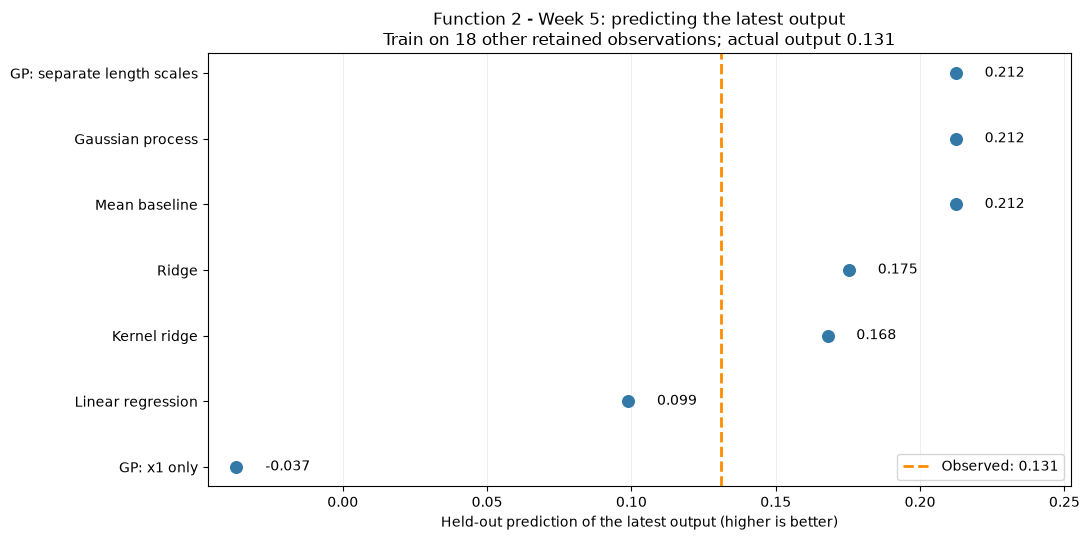

In [8]:
# Compare each model's held-out prediction with the latest result.
latest_chart = latest_prediction_review.sort_values("Latest held-out prediction", ascending=False)
fig, ax = plt.subplots(figsize=(11, 5.5))
positions = np.arange(len(latest_chart))
values = latest_chart["Latest held-out prediction"].to_numpy()
ax.scatter(values, positions, color="#3279a8", s=70, zorder=3)
ax.set_yticks(positions, latest_chart["Model"])
ax.invert_yaxis()
ax.axvline(
    latest_output, color="darkorange", linewidth=2, linestyle="--",
    label=f"Observed: {latest_output:.3f}",
)
chart_min = min(latest_output, values.min())
chart_max = max(latest_output, values.max())
chart_padding = 0.04 * (chart_max - chart_min)
for position, value in zip(positions, values):
    ax.text(value + chart_padding, position, f"{value:.3f}", va="center", fontsize=10)
ax.set_xlim(chart_min - chart_padding, chart_max + 4 * chart_padding)
ax.set_xlabel("Held-out prediction of the latest output (higher is better)")
ax.set_title(
    f"Function 2 - Week 5: predicting the latest output\n"
    f"Train on {other_observations.sum()} other retained observations; actual output {latest_output:.3f}"
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(figures / "latest-output-predictions.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Evaluate and interpret the results

Check overall held-out errors, the latest-result fold and model assumptions before choosing
a query. A better fit to training observations does not establish better prediction. The GP
supplies the mean and uncertainty needed for UCB; a different regressor may have the lowest
validation error. Keep that distinction explicit.

Select the lowest-LOO-RMSE GP among the three declared GP families for the UCB comparison. A non-GP may still predict held-out outputs more accurately; this policy uses the GP to obtain conditional uncertainty, not because GP status alone makes it superior. An x1-only fit has no x2-dependent uncertainty, so any resulting x2 preference may be a candidate-pool tie rather than learned evidence.


In [9]:
# Summarise the evidence before moving on to query selection.
lowest_rmse = model_comparison.iloc[0]
lowest_mae = model_comparison.loc[model_comparison["LOO MAE"].idxmin()]
closest_latest = latest_prediction_review.iloc[0]
lowest_rmse_latest = latest_prediction_review.loc[
    latest_prediction_review["Model"].eq(lowest_rmse["Model"])
].iloc[0]

print(f"Lowest overall LOO RMSE: {lowest_rmse['Model']} ({lowest_rmse['LOO RMSE']:.4f}).")
print(f"RMSE reduction against mean baseline: {lowest_rmse['RMSE reduction (%)']:.1f}%.")
print(f"Lowest overall LOO MAE: {lowest_mae['Model']} ({lowest_mae['LOO MAE']:.4f}).")
print(
    f"Closest prediction of the latest held-out result: {closest_latest['Model']}, "
    f"{closest_latest['Latest held-out prediction']:.4f} versus actual {latest_output:.4f}."
)
print(f"Its absolute error on that result: {closest_latest['Latest absolute error (%)']:.1f}%.")
print(
    f"The latest result contributes {lowest_rmse_latest['Latest share of squared error (%)']:.1f}% "
    "of the lowest-RMSE model's total held-out squared error."
)
print("Overall prediction error and ability to locate a better maximum are different assessments.")
print("This comparison does not establish the location or value of the global maximum.")
print("Model comparison is complete; query selection follows below.")

Lowest overall LOO RMSE: GP: x1 only (0.1238).
RMSE reduction against mean baseline: 47.7%.
Lowest overall LOO MAE: GP: x1 only (0.0954).
Closest prediction of the latest held-out result: Linear regression, 0.0989 versus actual 0.1312.
Its absolute error on that result: 24.6%.
The latest result contributes 9.7% of the lowest-RMSE model's total held-out squared error.
Overall prediction error and ability to locate a better maximum are different assessments.
This comparison does not establish the location or value of the global maximum.
Model comparison is complete; query selection follows below.


In [10]:
# Select the lowest-LOO-RMSE GP among the established competing explanations.
selected_model = fitted_models[best_gp_name]
relative_gp_error = gaussian_process_rmse / baseline_rmse
print('Query model:', best_gp_name)
print('Lowest-RMSE model overall:', model_comparison.iloc[0]['Model'])
print(f'Selected GP / baseline held-out RMSE: {relative_gp_error:.6f}')
gp_estimator = (selected_model.named_steps['gaussianprocessregressor']
                if hasattr(selected_model, 'named_steps') else selected_model)
noise_parameter = ('gaussianprocessregressor__alpha'
                   if hasattr(selected_model, 'named_steps') else 'alpha')
print('Fitted kernel:', gp_estimator.kernel_)
if relative_gp_error >= 1:
    print('Predictive support is weak: this GP does not beat the mean baseline. Treat the UCB proposal as exploratory.')
else:
    print('This GP beats the mean baseline on these observed-data folds; this does not guarantee a better maximum.')


Query model: GP: x1 only
Lowest-RMSE model overall: GP: x1 only
Selected GP / baseline held-out RMSE: 0.523233
Fitted kernel: 0.952**2 * RBF(length_scale=0.03)
This GP beats the mean baseline on these observed-data folds; this does not guarantee a better maximum.


### Read the fitted two-input relationship

Compare kernel ridge and the fitted GP on one shared contour scale. Coloured dots are measured
outputs; backgrounds are predictions. The gold star marks the incumbent. Blank regions lie
outside the sampled convex hull, not outside the allowed search domain.

The two GP slices pass through the incumbent and share output limits. Only observations
actually on each slice are shown as measured curve points. The pointwise mean ± 1.96 SD band
is conditional on the fitted kernel and noise assumption and excludes fresh observation noise.


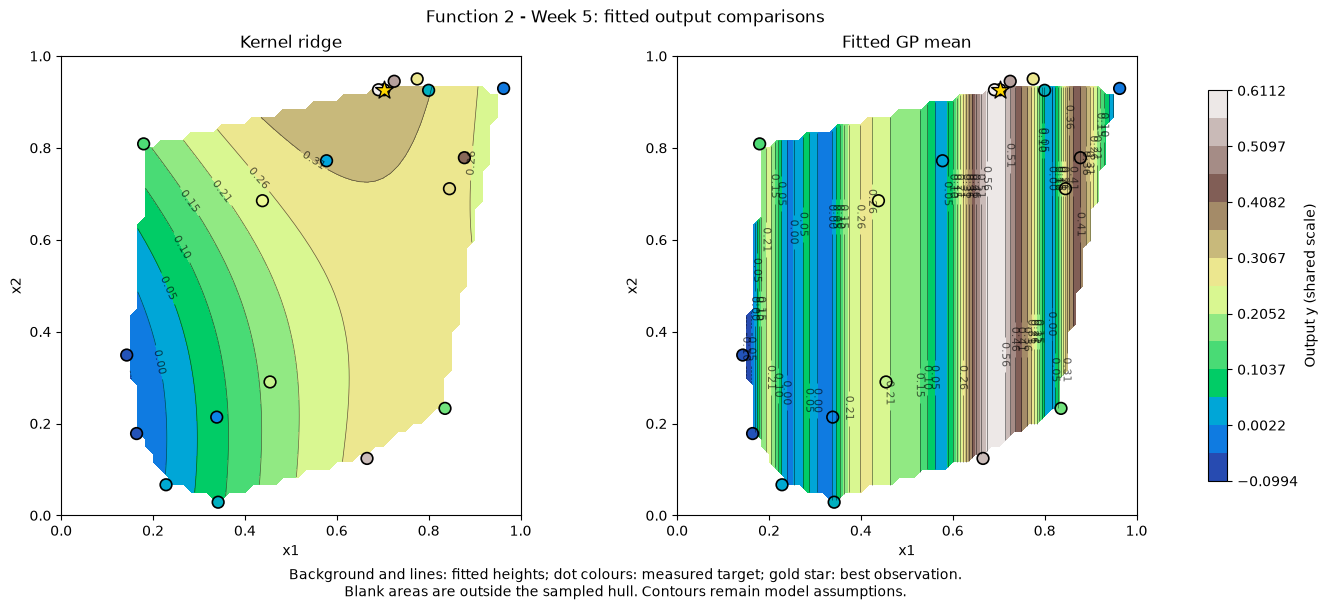

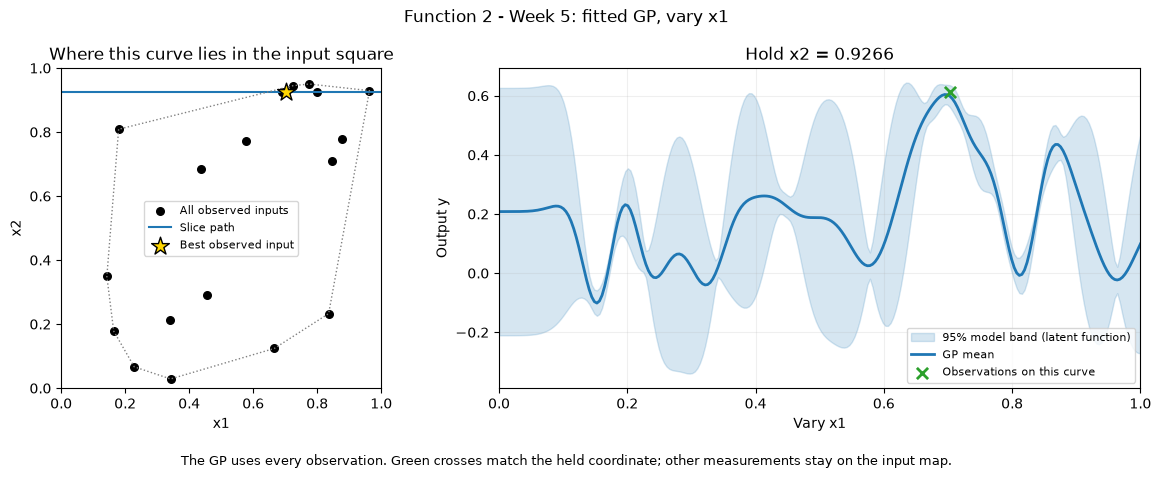

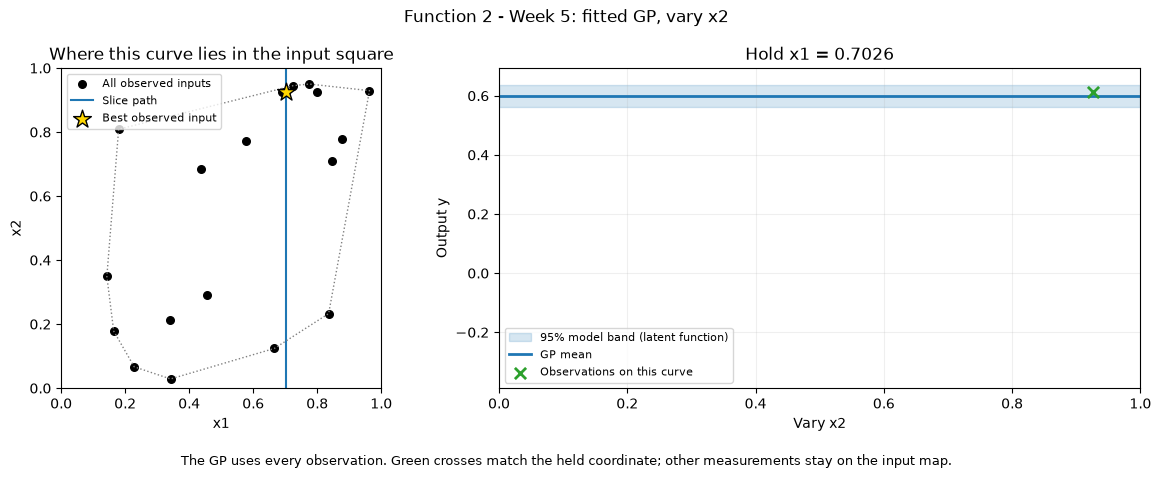

In [11]:
best_position = int(np.argmax(raw_y))
anchor = inputs[best_position].copy()
gp_grid = prediction_grid(selected_model, inputs, uncertainty=True)
kernel_ridge_grid = prediction_grid(fitted_models['Kernel ridge'], inputs)
display(plot_contour_comparison(inputs, [
    ('Kernel ridge', kernel_ridge_grid, raw_y), ('Fitted GP mean', gp_grid, raw_y),
], title='Function 2 - Week 5: fitted output comparisons', target_label='Output y',
   contour_format='%.2f', save_to=figures / 'fitted-output-contours.png'))
sections = [gp_slice(selected_model, inputs, raw_y, anchor, axis) for axis in (0, 1)]
lower = min(np.min(s['mean'] - 1.96*s['std']) for s in sections)
upper = max(np.max(s['mean'] + 1.96*s['std']) for s in sections)
pad = 0.05 * (upper - lower)
for axis in (0, 1):
    display(plot_gp_slice(selected_model, inputs, raw_y, anchor, axis,
        title=f'Function 2 - Week 5: fitted GP, vary x{axis+1}',
        height_limits=(lower-pad, upper+pad), target_label='Output y',
        save_to=figures / f'gp-slice-x{axis+1}.png'))
terrain = fitted_terrain(gp_grid, inputs, raw_y, raw_y,
    title='Function 2 - Week 5: fitted GP mean (raw output)', target_label='Output y',
    number_format='.3f', save_to=figures / 'fitted-gp-terrain.html')
terrain.show(config=PLOT_CONFIG)


### Compare a broad search, local refinement and pure coverage

Use the established upper confidence bound, $\mathrm{UCB}(x)=\mu(x)+1.96\sigma(x)$.
A large score can reflect either a promising mean or high uncertainty; it is not a returned
output or a guarantee of improvement. Compare a seeded broad Sobol pool (16,384 points plus
corners), a local pool within 0.15 of the incumbent in each coordinate, and one independently
optimised pure-coverage alternative. The local radius and exploration weight are declared
heuristics, not tuned against unseen returns.

Round to six decimals **before** predicting, remove duplicates and previously observed
inputs at portal precision, then score the exact remaining locations. The maximum is over
this finite pool. No course function is evaluated. The coverage alternative uses only input
geometry, so its gap reduction is separate from improvement in output.

If the x1-only GP wins, it cannot distinguish x2 values at a fixed x1. After choosing x1 by UCB, use a declared geometric tie-break: among 4,097 six-decimal x2 settings, choose the one with the largest distance to its nearest observed two-input point. This uses no output to infer an x2 effect. Apply the same tie-break to the exploration-weight comparison.


In [12]:
broad = pd.DataFrame(make_query_candidates(inputs, power=14, seed=42), columns=input_columns)
local_offsets = make_coverage_space(2, power=12, seed=43)
local = pd.DataFrame(np.clip(anchor + 0.30 * (local_offsets - 0.5), 0, 0.999999), columns=input_columns)
coverage_comparison = compare_coverage_batches(
    existing=inputs, cache_dir=week_dir / '.coverage-cache' / 'cohort', max_queries=1,
)
coverage = pd.DataFrame(coverage_comparison['proposed_batches'][1], columns=input_columns)
candidates = pd.concat([
    broad.assign(candidate_source='Full input space'),
    local.assign(candidate_source='Near incumbent'),
    coverage.assign(candidate_source='Single coverage query'),
], ignore_index=True)
candidates[input_columns] = candidates[input_columns].round(6).clip(0, 0.999999)
candidates = candidates.drop_duplicates(subset=input_columns)
observed_coordinates = set(map(tuple, inputs.round(6)))
candidates = candidates.loc[[tuple(p) not in observed_coordinates for p in candidates[input_columns].to_numpy()]]
exploration_weight = 1.96
scored = score_query_candidates(selected_model, candidates[input_columns].to_numpy(), weight=exploration_weight)
scored = scored.merge(candidates, on=input_columns, how='left', validate='one_to_one')
candidate_comparison = scored.loc[scored.groupby('candidate_source')['ucb'].idxmax()].sort_values('ucb', ascending=False)
display(candidate_comparison.round(6))
print(f'{len(scored):,} unique unobserved six-decimal candidate locations.')
print('Coverage alternative:', '-'.join(f'{v:.6f}' for v in coverage.iloc[0].round(6)))
before = coverage_comparison['results'][0]['max_distance']
after = coverage_comparison['results'][1]['max_distance']
print(f'Pure coverage reduces the separately assessed worst sampling gap by {1-after/before:.1%}.')


def resolve_unmodelled_x2(point):
    """For the x1-only hypothesis, use coverage to resolve equal GP scores."""
    point = np.asarray(point, dtype=float).copy()
    if best_gp_name != 'GP: x1 only':
        return point
    alternatives = np.column_stack([
        np.full(4097, point[0]), np.linspace(0, 0.999999, 4097).round(6),
    ])
    alternatives = alternatives[[tuple(p) not in observed_coordinates for p in alternatives]]
    nearest_distances = cdist(alternatives, inputs).min(axis=1)
    return alternatives[int(np.argmax(nearest_distances))]


q=0: computed and saved


q=1: computed and saved


,x1,x2,posterior_mean,posterior_sd,ucb,candidate_source
0,0.636151,0.624642,0.366651,0.142027,0.645024,Full input space
1,0.636176,0.912984,0.366839,0.141931,0.645024,Near incumbent
9997,0.997512,0.104366,0.087631,0.182774,0.445868,Single coverage query


20,489 unique unobserved six-decimal candidate locations.
Coverage alternative: 0.997512-0.104366
Pure coverage reduces the separately assessed worst sampling gap by 0.0%.


In [13]:
recommended = scored.iloc[0]
pool_point = recommended[input_columns].to_numpy(dtype=float)
next_query = resolve_unmodelled_x2(pool_point)
proposal_source = ('x1-only UCB with geometric x2 tie-break'
                   if best_gp_name == 'GP: x1 only' else recommended.candidate_source)
assert np.isfinite(next_query).all() and ((next_query >= 0) & (next_query < 1)).all()
assert np.array_equal(next_query, next_query.round(6)) and tuple(next_query) not in observed_coordinates
portal_input = '-'.join(f'{value:.6f}' for value in next_query)
next_mean, next_std = selected_model.predict(next_query[None, :], return_std=True)
inside_hull = bool(Delaunay(inputs).find_simplex(next_query) >= 0)
print('Proposed next query (input-column order):')
print(', '.join(f'{name}={value:.6f}' for name, value in zip(input_columns, next_query)))
print('Portal input:', portal_input)
print('Candidate source:', proposal_source)
if best_gp_name == 'GP: x1 only':
    print('x2 is chosen geometrically among equal GP predictions, not from evidence of an x2 effect.')
print(f'Best observed output: {raw_y.max():.6f}')
print(f'Predicted output at the proposed query: {next_mean[0]:.6f}')
print(f'Posterior standard deviation: {next_std[0]:.6f}')
print(f'Predicted mean improvement: {next_mean[0]-raw_y.max():+.6f}')
print(f'UCB acquisition score: {next_mean[0]+exploration_weight*next_std[0]:.6f}')
print('Inside sampled hull:', inside_hull)
print('This is a model-based proposal, not a guaranteed improvement or a submission.')
noise_rows = []
for fraction in (0.03, noise_fraction, 0.30):
    model = selected_model if fraction == noise_fraction else clone(selected_model).set_params(**{noise_parameter: fraction**2}).fit(inputs, raw_y)
    mean, std = model.predict(next_query[None, :], return_std=True)
    noise_rows.append({'Assumed noise fraction': fraction, 'Predicted output': mean[0], 'Posterior SD': std[0]})
print('Noise sensitivity at the same proposed point (refitting under each assumption):')
display(pd.DataFrame(noise_rows).round(6))
weight_rows = []
for weight in (0.0, 1.0, 1.96, 3.0):
    scores = scored.posterior_mean + weight * scored.posterior_sd
    alternative = scored.loc[scores.idxmax()]
    alternative_point = resolve_unmodelled_x2(alternative[input_columns].to_numpy(dtype=float))
    weight_rows.append({'Weight': weight, **dict(zip(input_columns, alternative_point)),
                        'Predicted output': alternative.posterior_mean, 'Posterior SD': alternative.posterior_sd})
exploration_sensitivity = pd.DataFrame(weight_rows)
print('Exploration-weight sensitivity (same candidate pool and predictions):')
display(exploration_sensitivity.round(6))
distinct_choices = len(exploration_sensitivity[input_columns].drop_duplicates())
print(f'{distinct_choices} distinct locations across {len(exploration_sensitivity)} weights.')


Proposed next query (input-column order):
x1=0.636151, x2=0.495605
Portal input: 0.636151-0.495605
Candidate source: x1-only UCB with geometric x2 tie-break
x2 is chosen geometrically among equal GP predictions, not from evidence of an x2 effect.
Best observed output: 0.611205
Predicted output at the proposed query: 0.366651
Posterior standard deviation: 0.142027
Predicted mean improvement: -0.244555
UCB acquisition score: 0.645024
Inside sampled hull: True
This is a model-based proposal, not a guaranteed improvement or a submission.
Noise sensitivity at the same proposed point (refitting under each assumption):


C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,Assumed noise fraction,Predicted output,Posterior SD
0,0.03,0.423472,0.146468
1,0.10,0.366651,0.142027
2,0.30,0.336121,0.113884


Exploration-weight sensitivity (same candidate pool and predictions):


,Weight,x1,x2,Predicted output,Posterior SD
0,0.00,0.696096,0.474853,0.604327,0.016750
1,1.00,0.694643,0.475097,0.604078,0.017071
2,1.96,0.636151,0.495605,0.366651,0.142027
3,3.00,0.073597,0.585937,0.219787,0.212060


4 distinct locations across 4 weights.


### Separate the predicted output, uncertainty and acquisition score

Each panel has its own units and colour scale. Black dots are observations, the gold star is
the incumbent and the magenta X is the proposed model-led query. The dotted line marks the
sampled convex hull; coloured predictions outside it are extrapolations. The gold star is
no longer a queued coverage point: that fixed sequence is complete.


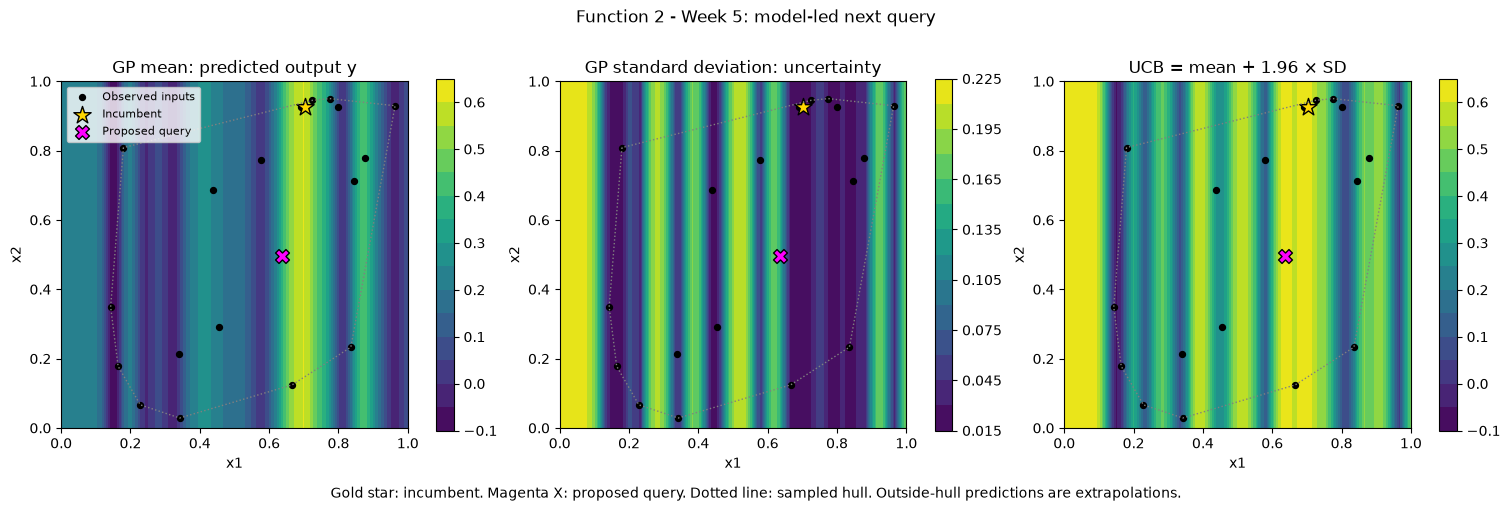

In [14]:
fields = [gp_grid['mean'], gp_grid['std'], gp_grid['mean'] + exploration_weight*gp_grid['std']]
titles = ['GP mean: predicted output y', 'GP standard deviation: uncertainty', 'UCB = mean + 1.96 × SD']
fig, axes = plt.subplots(1, 3, figsize=(15, 5), layout='constrained')
for ax, field, title in zip(axes, fields, titles):
    fill = ax.contourf(gp_grid['xx'], gp_grid['yy'], field, levels=15, cmap='viridis')
    fig.colorbar(fill, ax=ax, shrink=0.8)
    outline_hull(ax, inputs)
    ax.scatter(*inputs.T, color='black', s=18, label='Observed inputs')
    ax.scatter(*anchor, marker='*', color='gold', edgecolor='black', s=170, label='Incumbent')
    ax.scatter(*next_query, marker='X', color='magenta', edgecolor='black', s=100, clip_on=False, zorder=5, label='Proposed query')
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='x1', ylabel='x2', title=title)
    ax.set_aspect('equal')
axes[0].legend(fontsize=8, loc='upper left')
fig.suptitle('Function 2 - Week 5: model-led next query')
fig.supxlabel('Gold star: incumbent. Magenta X: proposed query. Dotted line: sampled hull. Outside-hull predictions are extrapolations.', fontsize=10)
fig.savefig(figures / 'model-query-proposal.png', dpi=160, bbox_inches='tight')
plt.show()


## 10. Deploy and iterate

Deployment is not applicable. This pooled-data comparison makes no portal submission and does
not replace the official proposal. Preserve the pinned peer snapshot and revisit the assumptions
after a future confirmed return. Peer data add observations, not weekly query opportunities.


In [15]:
analysis_summary = {
    'function': 2, 'week': 5, 'observations': len(data),
    'query_model': best_gp_name,
    'analysis_scope': 'cohort_snapshot_comparison',
    'proposal_status': 'exploratory_not_submitted', 'portal_input': portal_input,
    'point': next_query.tolist(), 'predicted_output': float(next_mean[0]),
    'posterior_std': float(next_std[0]), 'ucb_weight': exploration_weight,
    'candidate_source': proposal_source, 'candidate_count': len(scored),
    'x2_tie_break_candidates': 4097 if best_gp_name == 'GP: x1 only' else 0,
    'inside_sampled_hull': inside_hull, 'best_observed_output': float(raw_y.max()),
    'gp_rmse': gaussian_process_rmse, 'baseline_rmse': baseline_rmse,
    'gp_baseline_rmse_ratio': relative_gp_error,
    'lowest_rmse_model': model_comparison.iloc[0]['Model'],
    'distinct_weight_choices': distinct_choices,
    'remaining_queries': remaining_queries(week_dir),
    'own_observations': int(own_mask.sum()), 'peer_observations': int(peer_mask.sum()),
    'model_comparison': model_comparison.to_dict(orient='records'),
    'weight_sensitivity': exploration_sensitivity.to_dict(orient='records'),
    'noise_sensitivity': noise_rows,
    'fitted_kernel': str(gp_estimator.kernel_),
}
print(json.dumps(analysis_summary, indent=2))


{
  "function": 2,
  "week": 5,
  "observations": 19,
  "query_model": "GP: x1 only",
  "analysis_scope": "cohort_snapshot_comparison",
  "proposal_status": "exploratory_not_submitted",
  "portal_input": "0.636151-0.495605",
  "point": [
    0.636151,
    0.495605
  ],
  "predicted_output": 0.3666505371281177,
  "posterior_std": 0.14202744829292002,
  "ucb_weight": 1.96,
  "candidate_source": "x1-only UCB with geometric x2 tie-break",
  "candidate_count": 20489,
  "x2_tie_break_candidates": 4097,
  "inside_sampled_hull": true,
  "best_observed_output": 0.6112052157614438,
  "gp_rmse": 0.12377638136000961,
  "baseline_rmse": 0.23656079718021028,
  "gp_baseline_rmse_ratio": 0.5232328552973114,
  "lowest_rmse_model": "GP: x1 only",
  "distinct_weight_choices": 4,
  "remaining_queries": 9,
  "own_observations": 14,
  "peer_observations": 5,
  "model_comparison": [
    {
      "Model": "GP: x1 only",
      "Training MAE": 0.0069985201472548015,
      "LOO MAE": 0.09536843462922773,
      "L

## Read the pooled and paired comparisons together

The full pooled LOO scores describe all 19 retained rows. The following section compares the
same 14 official target rows and a common candidate pool. Those comparisons remain conditional
on this small, adaptively sampled dataset and the published peer reports; they are not an
independent future test or evidence that a query has improved the unknown function.


## Compare on the same official held-out targets

For each original observation, compare a prediction trained on the other 13 official rows with
one trained on those same 13 plus all five peer rows. Use each unchanged declared model family.
The scored target values are identical in both columns; peer rows can enter training, but never
replace those targets. This separates the training-data change from a change in the scored sample.
There is still no independent test set, and close peer points can make these checks optimistic.


In [16]:
own_inputs = own_data[input_columns].to_numpy(dtype=float)
own_y = own_data.y.to_numpy(dtype=float)
own_comparison, own_held_out, own_fitted = compare_models(models, own_inputs, own_y)
paired_rows = []
for name in models:
    pooled_own_predictions = held_out_predictions[name][own_mask]
    pd.testing.assert_series_equal(data.loc[own_mask, 'observation_id'].reset_index(drop=True), own_data.observation_id, check_names=False)
    paired_rows.append({
        'Model': name,
        'Own-target RMSE: 13 training rows': root_mean_squared_error(own_y, own_held_out[name]),
        'Own-target RMSE: 13 own + 5 peer training rows': root_mean_squared_error(own_y, pooled_own_predictions),
        'Own-target MAE: own training': mean_absolute_error(own_y, own_held_out[name]),
        'Own-target MAE: pooled training': mean_absolute_error(own_y, pooled_own_predictions),
    })
paired_comparison = pd.DataFrame(paired_rows)
display(paired_comparison.round(6))
own_gp_name = own_comparison.loc[gp_names, 'LOO RMSE'].idxmin()
own_selected = own_fitted[own_gp_name]
own_next = None
original_nb = __import__('nbformat').read(week_dir / 'model_predictions.ipynb', as_version=4)
for cell in original_nb.cells:
    for output in cell.get('outputs', []):
        text = output.get('text', '')
        if text.startswith('{\n  "function": 2,'):
            own_summary = json.loads(text)
            own_next = np.asarray(own_summary['point'], dtype=float)
if own_next is None:
    raise ValueError('The official notebook needs its saved proposal summary for this comparison.')
assert own_summary['observations'] == len(own_data) and own_summary['query_model'] == own_gp_name
assert np.isclose(own_summary['gp_rmse'], own_comparison.loc[own_gp_name,'LOO RMSE'])


C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a bette

C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


,Model,Own-target RMSE: 13 training rows,Own-target RMSE: 13 own + 5 peer training rows,Own-target MAE: own training,Own-target MAE: pooled training
0,Mean baseline,0.215118,0.210850,0.177465,0.173944
1,Linear regression,0.187074,0.183965,0.144931,0.132388
2,Ridge,0.185709,0.184449,0.141081,0.136457
3,Kernel ridge,0.198864,0.191284,0.154196,0.138413
4,Gaussian process,0.223697,0.171605,0.185444,0.138296
5,GP: x1 only,0.145783,0.121879,0.119795,0.092553
6,GP: separate length scales,0.147264,0.125679,0.120021,0.099721


## Compare both fits on a common candidate pool

Use the same frozen union of the current candidate pool, the official coverage alternative and
both provisional points, excluding every observed pooled input at portal precision. Score it
with the official-data GP and the pooled-data GP, using weight 1.96 for both. This comparison
controls the candidate set; neither policy receives an extra point solely because its own
search geometry changed. A score maximiser's x2 is arbitrary if that GP ignores x2.

Also predict at the **two actual proposals**, retaining their chosen x2 coordinates, to expose
changes in mean and uncertainty. Predicted values are not returned evaluations.


,Fit,Model,x1,x2,posterior_mean,posterior_sd,ucb,Candidates
0,Official 14-row fit,GP: x1 only,0.729749,0.474365,0.472454,0.135640,0.738309,20491
1,Pooled 19-row fit,GP: x1 only,0.636151,0.495605,0.366651,0.142027,0.645024,20491


,Point,Fit,x1,x2,Mean,SD,UCB
0,Official provisional point,Official 14-row fit,0.729749,0.474365,0.472454,0.135640,0.738309
1,Official provisional point,Pooled 19-row fit,0.729749,0.474365,0.484601,0.028008,0.539496
2,Cohort exploratory point,Official 14-row fit,0.636151,0.495605,0.321767,0.154782,0.625138
3,Cohort exploratory point,Pooled 19-row fit,0.636151,0.495605,0.366651,0.142027,0.645024


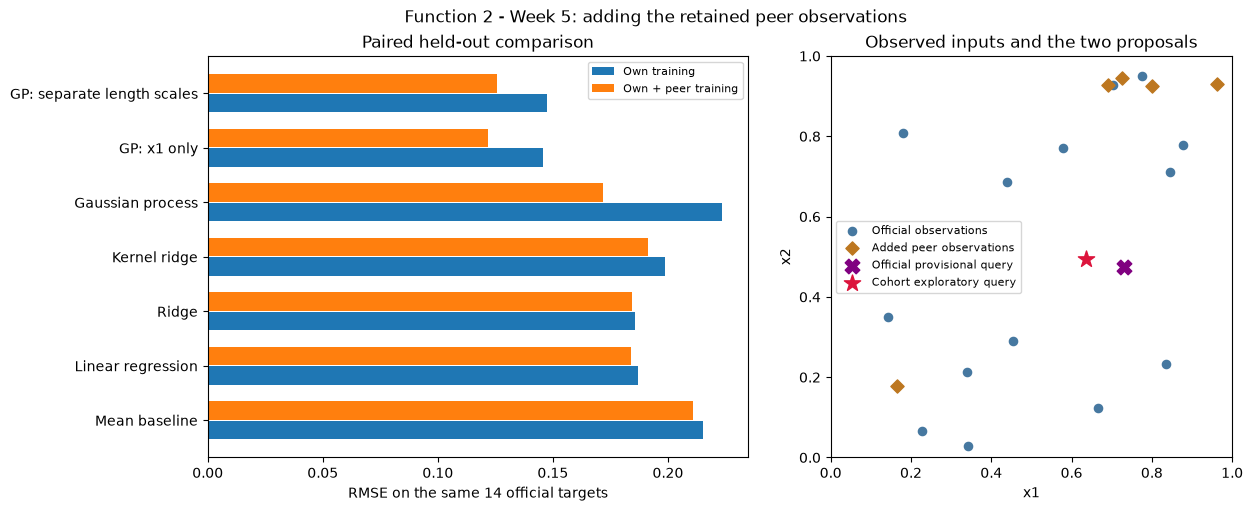

{
  "function": 2,
  "week": 5,
  "analysis": "official_vs_retained_cohort",
  "official": {
    "function": 2,
    "week": 5,
    "observations": 14,
    "query_model": "GP: x1 only",
    "proposal_status": "proposed_not_submitted",
    "portal_input": "0.729749-0.474365",
    "point": [
      0.729749,
      0.474365
    ],
    "predicted_output": 0.4724544855982812,
    "posterior_std": 0.13563989964509018,
    "ucb_weight": 1.96,
    "candidate_source": "x1-only UCB with geometric x2 tie-break",
    "candidate_count": 20489,
    "x2_tie_break_candidates": 4097,
    "inside_sampled_hull": true,
    "best_observed_output": 0.6112052157614438,
    "gp_rmse": 0.14578291498430085,
    "baseline_rmse": 0.21511752990375593,
    "gp_baseline_rmse_ratio": 0.6776896101843697,
    "lowest_rmse_model": "GP: x1 only",
    "distinct_weight_choices": 4,
    "remaining_queries": 9
  },
  "cohort": {
    "function": 2,
    "week": 5,
    "observations": 19,
    "query_model": "GP: x1 only",
    "an

In [17]:
own_coverage = compare_coverage_batches(existing=own_inputs,
    cache_dir=week_dir/'.coverage-cache', max_queries=1, verbose=False)
own_coverage_point = own_coverage['proposed_batches'][1]
common_points = np.vstack([candidates[input_columns].to_numpy(), own_coverage_point, own_next, next_query]).round(6)
common_points = np.unique(np.clip(common_points,0,0.999999),axis=0)
common_points = common_points[[tuple(p) not in observed_coordinates for p in common_points]]
common_rows = []
for label, gp in [('Official 14-row fit', own_selected), ('Pooled 19-row fit', selected_model)]:
    common_scores = score_query_candidates(gp, common_points, weight=exploration_weight)
    top = common_scores.iloc[0]
    common_rows.append({'Fit':label, 'Model':own_gp_name if label.startswith('Official') else best_gp_name,
                        **top.to_dict(), 'Candidates':len(common_points)})
common_comparison = pd.DataFrame(common_rows)
display(common_comparison.round(6))
proposal_rows = []
for point_label, point in [('Official provisional point',own_next),('Cohort exploratory point',next_query)]:
    for fit_label, gp in [('Official 14-row fit',own_selected),('Pooled 19-row fit',selected_model)]:
        mean,std = gp.predict(point[None,:], return_std=True)
        proposal_rows.append({'Point':point_label,'Fit':fit_label,'x1':point[0],'x2':point[1],
                              'Mean':mean[0],'SD':std[0],'UCB':mean[0]+exploration_weight*std[0]})
proposal_comparison = pd.DataFrame(proposal_rows)
display(proposal_comparison.round(6))
fig,axes = plt.subplots(1,2,figsize=(13,5),layout='constrained')
positions=np.arange(len(paired_comparison))
axes[0].barh(positions-0.18,paired_comparison.iloc[:,1],height=0.34,label='Own training')
axes[0].barh(positions+0.18,paired_comparison.iloc[:,2],height=0.34,label='Own + peer training')
axes[0].set(yticks=positions,yticklabels=paired_comparison.Model,xlabel='RMSE on the same 14 official targets',title='Paired held-out comparison')
axes[0].legend(fontsize=8)
axes[1].scatter(*own_inputs.T,color='#4678a0',label='Official observations',s=35)
axes[1].scatter(*inputs[peer_mask].T,color='#bd7720',marker='D',label='Added peer observations',s=45)
axes[1].scatter(*own_next,color='purple',marker='X',s=110,label='Official provisional query')
axes[1].scatter(*next_query,color='crimson',marker='*',s=150,label='Cohort exploratory query')
axes[1].set(xlim=(0,1),ylim=(0,1),xlabel='x1',ylabel='x2',title='Observed inputs and the two proposals')
axes[1].set_aspect('equal');axes[1].legend(fontsize=8)
fig.suptitle('Function 2 - Week 5: adding the retained peer observations')
fig.savefig(figures/'official-versus-cohort.png',dpi=160,bbox_inches='tight')
plt.show()
comparison_summary = {'function':2,'week':5,'analysis':'official_vs_retained_cohort',
    'official':own_summary,'cohort':analysis_summary,
    'paired_targets':paired_comparison.to_dict(orient='records'),
    'common_candidates':common_comparison.to_dict(orient='records'),
    'proposal_predictions':proposal_comparison.to_dict(orient='records')}
print(json.dumps(comparison_summary,indent=2))


## Discussion: what changed with the retained cohort data?

The five additional peer returns leave the best observed value unchanged at
**0.6112052157614438**. Both fits still favour the **x1-only GP**; the extra data have not
established an independent x2 effect. Its fitted length scale still reaches the declared
lower bound of **0.03**, so the apparent narrow structure remains assumption-dependent.

For the **same 14 official held-out targets**, adding the peer rows to training reduces
this model's RMSE from **0.145783** to **0.121879** (**16.4% lower**).
That is the paired comparison; the full 19-target pooled RMSE is **0.123776**, against
its own mean baseline of **0.236561**. The two full-dataset metrics use different target
sets and should not be treated as a direct measure of improvement.

The official proposal remains **`0.729749-0.474365`**. At that same point, the pooled fit
changes the mean only from **0.472454** to **0.484601**, while its latent-function SD falls
from **0.135640** to **0.028008**. Consequently the exploration-weighted UCB drops from
**0.738309** to **0.539496**. The strongest change is reduced uncertainty around the
original candidate, rather than a worse predicted output there.

The cohort policy instead proposes **`0.636151-0.495605`**, with mean **0.366651**, SD
**0.142027** and UCB **0.645024**. Its predicted mean is below the incumbent, so it is an
**exploration alternative**, not a predicted improvement in the maximum. The same shift
in preferred x1 appears when both models score the **same 20,491 candidate locations**;
it is not solely an effect of different candidate coverage. x2 is selected geometrically
among equal predictions of the x1-only model, not inferred as an optimum.

At lower exploration weights, the pooled GP selects x1 around **0.695**; at weight 3 it
moves to about **0.074**. All four tested weights produce different locations. The choice
therefore remains sensitive to the exploration balance and the assumed noise model.

The five peer records are frozen public self-reports collected on 20 October, not a fresh
cohort return or an independently verified test set. A few near-peak observations can
substantially change this small fitted model. The result supports examining how the peer
observations reduce uncertainty; it does not automatically justify replacing the official
proposal. **Both official notebooks and the official proposal remain unchanged.**
